# M7 — refitting ZTT to L23: "ZTT (L23 µ∞)"

The ZTT backbone (Twardowski & Tonizzo 2018) carries one term we never had: the
sixteen coefficients of its Equation (8) for **µ∞**, the asymptotic average
cosine, were never published. M0–M6 used the authors' 2017 surface instead
("ZTT (TT2017 µ∞)"). M7 refits µ∞ — and, once we looked, µd and the particle
phase function too — to the L23 HydroLight ensemble.

**Result:** on held-out L23 scenes the backbone's rRMS falls from **5.93% to
2.90%** (0°/30°/60°: 4.26/4.67/8.11 → 2.91/2.56/3.18%), and `rrs_ZTT` now
defaults to the refit. The hybrid is untouched: its emulator was trained on
the TT2017 backbone and is pinned to it.

This notebook walks through the four things that made it work, and the one
diagnostic that said where to stop. Sources: `design/rt_elastic_implementation.md`
§7b, `claude_prompts/RT/rt_fit_ztt.md`, `design/ztt_l23/`.

In [1]:
import sys, json, csv, pathlib
ROOT = pathlib.Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from robust.rt import asymptotic as A, conventions as C, phase as P, ztt as Z
from robust.rt.data import l23 as L

FIT = ROOT / "design" / "ztt_l23"
coeffs = json.loads((FIT / "coefficients.json").read_text())
metrics = json.loads((FIT / "metrics.json").read_text())

# CVD-safe (Okabe-Ito), as M4 settled; text in ink, never in series colour.
INK, MUTED = "#1a1a1a", "#9a9a9a"
BLUE, ORANGE, GREEN, VERM, SKY, PINK = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#dcdcdc", "figure.dpi": 110})

## 1. The profiles cannot measure µ∞ — on 97.6% of L23

L23 ships depth profiles to 50 m. By Gershun's law µ(z) = (Ed − Eu)/Eo tends to
µ∞ at depth, and µ∞ is an IOP, so three suns must agree once the light field is
asymptotic. They agree to < 1% on only **2.4%** of (scene, λ) — all in
particle-dominated water. Clear water is ~1.5 optical depths deep at 50 m.

In [2]:
product = L.load_profile_product(L.default_profile_product_path())
print({k: round(v, 4) for k, v in product.flag_fractions().items()})
print("median zenith spread of µ at depth: %.1f%%" % (100 * np.nanmedian(product.spread)))

{'unusable': 0.0, 'not_asymptotic': 0.9757, 'asymptotic': 0.0243}
median zenith spread of µ at depth: 9.3%


## 2. So µ∞ is computed, not measured: the asymptotic eigenproblem

µ∞ is the slowest-decaying mode of the azimuthally averaged RTE — computable
from L23's own inputs (water + two Fournier–Forand particle components,
b̃b = 0.010 and 0.018). `robust.rt.asymptotic` solves it; it is checked against
the exact isotropic solution and against the 2.4% where the profiles *are*
asymptotic (+1.34% systematic, ±0.3% scatter — carried as a stated offset).

In [3]:
from scipy.optimize import brentq
mu, w = A.double_gauss(A.N_STREAMS)
iso = A.build_kernel(lambda p: np.full_like(np.asarray(p, float), 1 / (4 * np.pi)), mu, w, truncation_deg=0)
for om in (0.2, 0.5, 0.9):
    k = brentq(lambda k: om / (2 * k) * np.log((1 + k) / (1 - k)) - 1, 1e-9, 1 - 1e-12)
    got = float(A.mu_infinity_eigen(np.asarray(1 - om), np.asarray([om]), mu, w, (iso,)))
    print(f"isotropic ω0={om}: eigen {got:.6f}  exact {(1 - om) / k:.6f}")
v = metrics["mu_inf_vs_profiles_asymptotic"]
print("eigen / profile µ∞ on %d asymptotic points: median %+.2f%%" % (v["n"], 100 * v["eigen"]["signed_pct_1_16_50_84_99"][2]))

isotropic ω0=0.2: eigen 0.799852  exact 0.800073
isotropic ω0=0.5: eigen 0.522191  exact 0.522191
isotropic ω0=0.9: eigen 0.190320  exact 0.190320
eigen / profile µ∞ on 6533 asymptotic points: median +1.34%


## 3. The refits: µ∞ (Eq. 8) and µd (Eq. 17 + a sky correction)

Both are linear least squares on the train scenes. µd turned out to matter
*more* than µ∞: TT's atmospheric factor puts µd **8.7% high at 60° sun** for
L23's sky, which is most of the old backbone's 60° failure. A two-number
correction c(θs′), fitted jointly with M*_d, removes it.

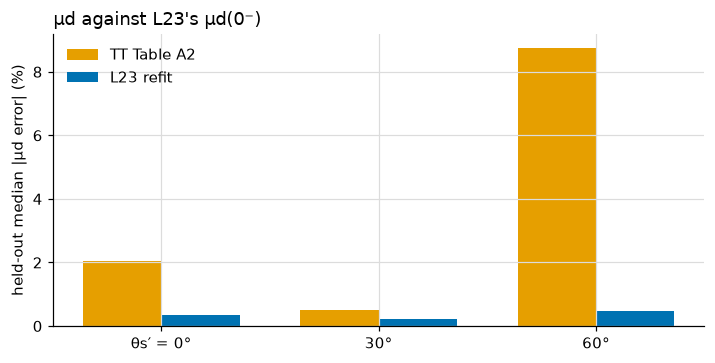

µ∞ held-out median |err|: L23 refit 0.21%, TT2017 1.08% (TT2017 99th pct +23.9%)


In [4]:
md = metrics["mu_d_heldout"]
fig, ax = plt.subplots(figsize=(6.6, 3.4))
z = np.arange(3)
ax.bar(z - 0.18, [100 * md[k]["TT"]["mape"] for k in ("0", "30", "60")], 0.36, color=ORANGE, label="TT Table A2")
ax.bar(z + 0.18, [100 * md[k]["L23_fit"]["mape"] for k in ("0", "30", "60")], 0.36, color=BLUE, label="L23 refit")
ax.set_xticks(z, ["θs′ = 0°", "30°", "60°"]); ax.set_ylabel("held-out median |µd error| (%)")
ax.legend(frameon=False); ax.set_title("µd against L23's µd(0⁻)", loc="left"); plt.tight_layout(); plt.show()
m = metrics["mu_inf_heldout_vs_eigen"]
print("µ∞ held-out median |err|: L23 refit %.2f%%, TT2017 %.2f%% (TT2017 99th pct %+.1f%%)" % (
    100 * m["L23_fit"]["mape"], 100 * m["TT2017"]["mape"], 100 * m["TT2017"]["signed_pct_1_16_50_84_99"][4]))

## 4. L23's own phase function

L23's particles are two Fournier–Forand populations; `PhaseParams.ff_B` /
`ff_weight` carry them and the L23 variant uses them (Sullivan otherwise). At
backscatter the two bracket Sullivan's measured shape within 2%.

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


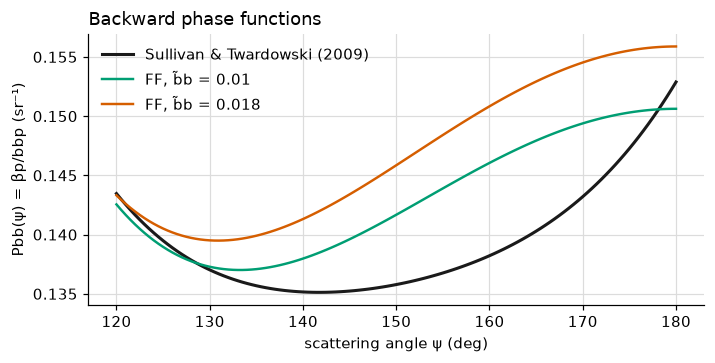

In [5]:
psi = np.linspace(120, 180, 121)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(psi, np.asarray(Z.P_bb_sullivan(psi)), color=INK, lw=2, label="Sullivan & Twardowski (2009)")
for B, col in ((0.010, GREEN), (0.018, VERM)):
    ax.plot(psi, np.asarray(P.P_bb_ff(psi, jnp.asarray([B]), jnp.ones(1))), color=col, lw=1.6, label=f"FF, b̃b = {B}")
ax.set_xlabel("scattering angle ψ (deg)"); ax.set_ylabel("Pbb(ψ) = βp/bbp (sr⁻¹)")
ax.legend(frameon=False); ax.set_title("Backward phase functions", loc="left"); plt.tight_layout(); plt.show()

## 5. The variant, and what did not move

`rrs_ZTT(..., variant="l23")` is the default; `variant="tt2017"` reproduces the
pre-M7 model bit for bit (a test pins its hash). The emulator records the
backbone it was trained on (`backbone_variant`, "tt2017" for the shipped
weights), and `forward(mode="hybrid")` uses that one — so the hybrid's numbers
are unchanged.

In [6]:
from robust.rt import emulator as E
batch = L.load_batch(reader=L.npz_reader(ROOT / "robust/tests/files/l23_small.npz"))
args = (batch.iops, batch.phase_params, batch.geometry, batch.wave)
truth = C.Rrs_to_rrs(batch.Rrs)
from robust.rt import validation as V
for v in ("tt2017", "l23"):
    print(f"fixture rRMS, variant={v!r}: {float(V.rrms(truth, Z.rrs_ZTT(*args, variant=v))):.2f}%")
print("shipped emulator backbone:", E.load_default().backbone_variant)

fixture rRMS, variant='tt2017': 5.30%
fixture rRMS, variant='l23': 2.95%


shipped emulator backbone: tt2017


## 6. The ladder — and the acceptance gate

Each step switches on one L23 term. **Gate: the L23 variant beats TT2017 on
held-out scenes at every zenith — passed.**

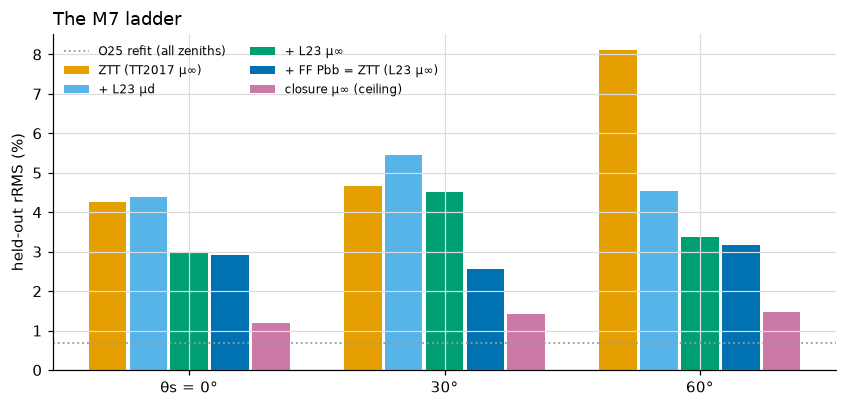

ZTT (TT2017 µ∞)              held-out 5.93%
+ L23 µd                     held-out 4.81%
+ L23 µ∞                     held-out 3.68%
+ FF Pbb = ZTT (L23 µ∞)      held-out 2.90%
closure µ∞ (ceiling)         held-out 1.37%


In [7]:
rows = {r["model"]: r for r in csv.DictReader((FIT / "ladder.csv").open())}
steps = ["ZTT (TT2017 µ∞)", "+ L23 µd", "+ L23 µ∞", "+ FF Pbb = ZTT (L23 µ∞)", "closure µ∞ (ceiling)"]
cols = [ORANGE, SKY, GREEN, BLUE, PINK]
fig, ax = plt.subplots(figsize=(7.8, 3.8))
x = np.arange(3); wd = 0.16
for k, (s, c) in enumerate(zip(steps, cols)):
    vals = [float(rows[s][f"held-out {z}°"]) for z in (0, 30, 60)]
    ax.bar(x + (k - 2) * wd, vals, wd * 0.92, color=c, label=s)
ax.axhline(float(rows["O25 form, refit on L23"]["held-out"]), color=MUTED, ls=":", lw=1.2, label="O25 refit (all zeniths)")
ax.set_xticks(x, ["θs = 0°", "30°", "60°"]); ax.set_ylabel("held-out rRMS (%)")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.set_title("The M7 ladder", loc="left"); plt.tight_layout(); plt.show()
for s in steps:
    print(f"{s:28s} held-out {float(rows[s]['held-out']):.2f}%")

## 7. Where to stop: Ψ_KLu cannot be fixed on its own

ZTT's Ψ_KLu (the near-surface K_Lu over K∞) is ~13% higher than L23's
measured KLu/a. The obvious repair — substitute the measurement — makes the
backbone *worse*: 7.8–9.5% at any sampling depth, against 2.90%. TT's other
fitted terms (f_L above all) are tuned to their Ψ_KLu; inside Eq. (12) "K_Lu" is
an effective parameter. The **closure µ∞** — the µ∞ that makes ZTT exact — shows
what remains is reachable only as calibration: 1.37%, a ceiling, not physics.

In [8]:
text = (FIT / "ladder.md").read_text()
print(text[text.index("## The oracle"):text.index("## Per B_p")])

## The oracle KLu/a step, by sampling depth (Q16)

Ψ_KLu/µ∞ replaced by L23's measured KLu(z)/a. ZTT's own implied K_Lu is Ψ_KLu a / µ∞(L23).

| KLu taken at | held-out rRMS | ZTT implied / measured K_Lu, 16 / 50 / 84% |
|---|---|---|
| 0 m | 9.54% | 1.013 / 1.131 / 1.255 |
| 1 m | 9.19% | 1.020 / 1.124 / 1.242 |
| 5 m | 8.37% | 1.033 / 1.116 / 1.207 |
| 10 m | 7.98% | 1.040 / 1.112 / 1.188 |
| 20 m | 7.83% | 1.043 / 1.110 / 1.172 |
| *(ZTT (L23 µ∞), for reference)* | 2.90% | |




## 8. What M7 may and may not claim

**May:** "ZTT (L23 µ∞)" — µ∞ from the asymptotic eigenproblem on L23's IOPs, µd
refit with a sky correction, L23's FF phase function — halves the analytic
backbone's held-out error on L23 (5.93 → 2.90%) and removes its 60° failure,
with `tt2017` kept bit for bit and the hybrid unchanged.

**May not:** claim the published 2018 ZTT (its coefficients remain unknown);
claim µ∞ accuracy better than the +1.3% eigen-vs-HydroLight offset; claim
anything off-nadir or at other sun angles (L23 has three; c(θs′) is exactly
determined by them); or claim the backbone competes with O25 refit (0.69%) or
the hybrid (0.30%). Next: PB24 (Q20 answer (a)).